# Pokémon battle prediction: from EDA to three reproducible submissions

**Question:** given the first 30 observed turns of a Gen 2 OU battle, will Player 1 eventually win?

This notebook explains the data checks, temporal representations and modelling decisions behind **C09, V334 highest mean and V337 CatBoost F06 P1+P2**, then reproduces their exact CSVs. This is the single complete notebook for EDA, modelling explanations and exact submission reproduction.

For readers familiar with tabular classification, it separates **descriptive observations**, **feature definitions**, **historical validation** and **reported Kaggle scores**. EDA is recomputed on training records only. No test outcomes or external Pokémon database are used. Descriptive patterns alone do not prove that a feature improves Accuracy.

**Contents:** 1. setup and data; 2. quality; 3. HP over time; 4. moves and observed KOs; 5. feature engineering; 6. validation and results; 7. reproduction; 8. limitations.

## 1. Setup and information available

The challenge provides 10,000 labelled training battles and 5,000 test battles. `player_won` describes the eventual outcome, not the state at turn 30. Predictors use only the first 30 snapshots.

P1 has six initial Pokémon cards, including items; P2 has an initial lead card, not a complete visible roster. Both sides have active-state snapshots. This makes team reconstruction asymmetric. `name` and `types` on Pokémon cards describe the Pokémon; `name` and `type` on move cards describe the move.

On Kaggle, attach the competition dataset and enable Internet for cloning and installation. Locally, run from the package or project directory. This notebook never uploads submissions. If a Kaggle clone already exists, synchronize it with the published version before running.

In [1]:
from pathlib import Path
import hashlib
import json
import subprocess
import sys

ON_KAGGLE = Path("/kaggle/input").is_dir()
REPOSITORY_URL = "https://github.com/MatteoAdilardi/FDS_pokemon_challenge_2026.git"
REFIT_MODELS = False  # True retrains on all 10,000 labels; False loads saved models.
LOCAL_DATA_DIR = None  # Optional local override: Path("/path/to/data").
if ON_KAGGLE:
    PACKAGE_DIR = Path("/kaggle/working/fds_selected_submissions")
    if not PACKAGE_DIR.exists():
        subprocess.run(["git", "clone", "--depth", "1", REPOSITORY_URL,
                        str(PACKAGE_DIR)], check=True)
else:
    candidates = [Path.cwd(), Path.cwd() / "to_kaggle"]
    PACKAGE_DIR = next((p.resolve() for p in candidates
                        if (p / "run_submissions.py").is_file()), None)
    if PACKAGE_DIR is None:
        raise FileNotFoundError("Run from to_kaggle or the project root.")
if not (PACKAGE_DIR / "submission_reproduction.ipynb").is_file():
    raise RuntimeError("Old package checkout: synchronize it before running.")
if sys.version_info < (3, 12):
    raise RuntimeError("Python 3.12 or newer is required by the pinned environment.")
if ON_KAGGLE:
    subprocess.run([sys.executable, "-m", "pip", "install", "--disable-pip-version-check",
                    "-r", str(PACKAGE_DIR / "requirements-notebook.txt")], check=True)
    matches = [p.parent for p in Path("/kaggle/input").rglob("train.jsonl")
               if (p.parent / "test.jsonl").is_file()
               and (p.parent / "sample_submission.csv").is_file()]
    if len(matches) != 1:
        raise RuntimeError(f"Expected one competition data directory; found {matches}")
    DATA_DIR = matches[0]
else:
    DATA_DIR = Path(LOCAL_DATA_DIR) if LOCAL_DATA_DIR else PACKAGE_DIR.parent / "data"
OUTPUT_DIR = (Path("/kaggle/working/eda_walkthrough") if ON_KAGGLE
              else PACKAGE_DIR / "outputs" / "eda_walkthrough")
FIGURE_DIR = OUTPUT_DIR / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
print("Package:", PACKAGE_DIR)
print("Data:", DATA_DIR)
print("Outputs:", OUTPUT_DIR)

Package: C:\Users\adila\Downloads\Master Degree Data Science\FDS\challenge\to_kaggle
Data: C:\Users\adila\Downloads\Master Degree Data Science\FDS\challenge\data
Outputs: C:\Users\adila\Downloads\Master Degree Data Science\FDS\challenge\to_kaggle\outputs\eda_walkthrough


In [2]:
import importlib.metadata
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

sys.path.insert(0, str(PACKAGE_DIR))
from src.refit_goal70_pm2_submission2_all13_v1 import read_jsonl

MANIFEST = json.loads((PACKAGE_DIR / "manifest.json").read_text(encoding="utf-8"))
RECIPE_IDS = ("c09", "v334_highest_mean", "v337_cat_f06_pair")
if set(MANIFEST["recipes"]) != set(RECIPE_IDS):
    raise RuntimeError("Expected C09, highest mean and V337 in the manifest.")
for relative, expected in MANIFEST["source_sha256"].items():
    if hashlib.sha256((PACKAGE_DIR / relative).read_bytes()).hexdigest() != expected:
        raise RuntimeError(f"Source integrity check failed: {relative}")
train_records, y_train = read_jsonl(DATA_DIR / "train.jsonl", training=True)
assert len(train_records) == 10000
assert len({r["battle_id"] for r in train_records}) == 10000
assert set(np.unique(y_train)) == {0, 1}
assert all("player_won" not in r for r in train_records)
print("Training battles:", len(train_records), "| Labels:", dict(Counter(y_train.tolist())))
print("Python:", sys.version.split()[0])
packages = ["numpy", "pandas", "scikit-learn", "xgboost", "catboost", "matplotlib"]
display(pd.DataFrame({"package": packages,
                      "version": [importlib.metadata.version(p) for p in packages]}))

,package,version
0,numpy,2.5.3
1,pandas,3.1.0
2,scikit-learn,1.9.1
3,xgboost,3.4.1
4,catboost,1.2.10
5,matplotlib,3.11.2


Training battles: 10000 | Labels: {0: 5000, 1: 5000}
Python: 3.14.8


## 2. Data quality and meaningful absence

We inspect **10,000 × 30 = 300,000 snapshots per side**, retaining duplicate records in descriptive statistics. Snapshots within one battle are correlated: 600,000 side snapshots are not independent training examples.

The following checks cover timeline order, six P1 cards, P2 lead, HP bounds, names and move availability. A failed check stops the walkthrough. These checks do not certify every label or the simulator.

| Value | Interpretation |
|---|---|
| `notype` in Pokémon `types` | No real type in that slot; not an unknown species. It may occur in either slot. |
| `nostatus` / `noeffect` | Explicit absence of a recorded status/effect. |
| Move object `null` | No move card recorded; not automatically a switch, miss or zero damage. |
| Power `0`, boost `0`, priority `0` | Valid values, not automatically missing. Nominal power is not actual damage. |
| `fnt` / HP `0` | Terminal state observed; repeated snapshots need not be new KOs. |

The original EDA found 59,377 null move cards P1 and 59,600 P2. We recompute them below. The reader removes the target from records before feature extraction; labels are used only for the balance check above and optional final refit.

In [3]:
def summarize_training_records(records):
    snapshot_rows, ko_rows = [], []
    for record in records:
        battle_id = int(record["battle_id"])
        timeline = record["battle_timeline"]
        if [t.get("turn") for t in timeline] != list(range(1, 31)):
            raise ValueError(f"Expected ordered first-30 timeline: {battle_id}")
        if len(record.get("p1_team_details") or []) != 6:
            raise ValueError(f"Expected six P1 cards: {battle_id}")
        if not isinstance(record.get("p2_lead_details"), dict):
            raise ValueError(f"Missing P2 lead card: {battle_id}")
        for side in ("p1", "p2"):
            previous_name = None
            first_terminal = {}
            for frame in timeline:
                state = frame[f"{side}_pokemon_state"]
                name = str(state.get("name") or "").strip().lower()
                hp = float(state["hp_pct"])
                status = str(state["status"]).strip().lower()
                if not name or not np.isfinite(hp) or not 0 <= hp <= 1:
                    raise ValueError(f"Invalid state: {battle_id}/{side}/{frame['turn']}")
                move = frame[f"{side}_move_details"]
                if move is not None and not isinstance(move, dict):
                    raise ValueError("Expected object or null move card.")
                terminal = status == "fnt" or hp <= 0
                is_first_terminal = terminal and name not in first_terminal
                if is_first_terminal:
                    first_terminal[name] = frame["turn"]
                snapshot_rows.append({
                    "battle_id": battle_id, "side": side, "turn": frame["turn"],
                    "name": name, "hp": hp, "status": status, "move_null": move is None,
                    "name_changed": (name != previous_name) if previous_name is not None else None,
                    "terminal": terminal, "fnt_hp_disagree": (status == "fnt") != (hp == 0),
                    "first_terminal": is_first_terminal,
                })
                previous_name = name
            for low, high in ((1, 10), (11, 20), (21, 30)):
                ko_rows.append({"battle_id": battle_id, "side": side,
                                "window": f"{low}–{high}",
                                "new_terminal_names": sum(low <= t <= high
                                                          for t in first_terminal.values())})
    return pd.DataFrame(snapshot_rows), pd.DataFrame(ko_rows)

snapshots, ko_counts = summarize_training_records(train_records)
snapshots["block"] = pd.cut(snapshots["turn"], [0, 10, 20, 30], labels=["1–10", "11–20", "21–30"])
quality = snapshots.groupby("side", sort=False).agg(
    snapshots=("hp", "size"), hp_min=("hp", "min"), hp_max=("hp", "max"),
    missing_move_cards=("move_null", "sum"), terminal_snapshots=("terminal", "sum"),
    fnt_hp_disagreements=("fnt_hp_disagree", "sum"))
quality["missing_move_rate"] = quality["missing_move_cards"] / quality["snapshots"]
assert quality["snapshots"].tolist() == [300000, 300000]
assert quality["missing_move_cards"].tolist() == [59377, 59600]
assert quality["fnt_hp_disagreements"].eq(0).all()
display(quality)

,snapshots,hp_min,hp_max,missing_move_cards,terminal_snapshots,fnt_hp_disagreements,missing_move_rate
side,,,,,,,
p1,300000,0.0,1.0,59377,16882,0,0.197923
p2,300000,0.0,1.0,59600,5040,0,0.198667


**Interpretation.** In these observations, HP bounds and the equivalence of `fnt` and zero HP are consistent. This does not prove that all KOs are visible. Terminal snapshot counts depend on exposure and persistence, not just the number of Pokémon lost. Null move rates are 19.79% for P1 and 19.87% for P2; a null object remains distinct from a present zero-valued attribute.

## 3. Why keep temporal HP information?

The final active state does not determine the previous trajectory. A new active name may increase HP without healing the previous Pokémon. The chart shows **mean active HP, not remaining team HP**.

Each point uses 10,000 observations for that side and turn. Every battle contributes ten snapshots per block below. These are descriptive means, without confidence intervals or causal interpretation.

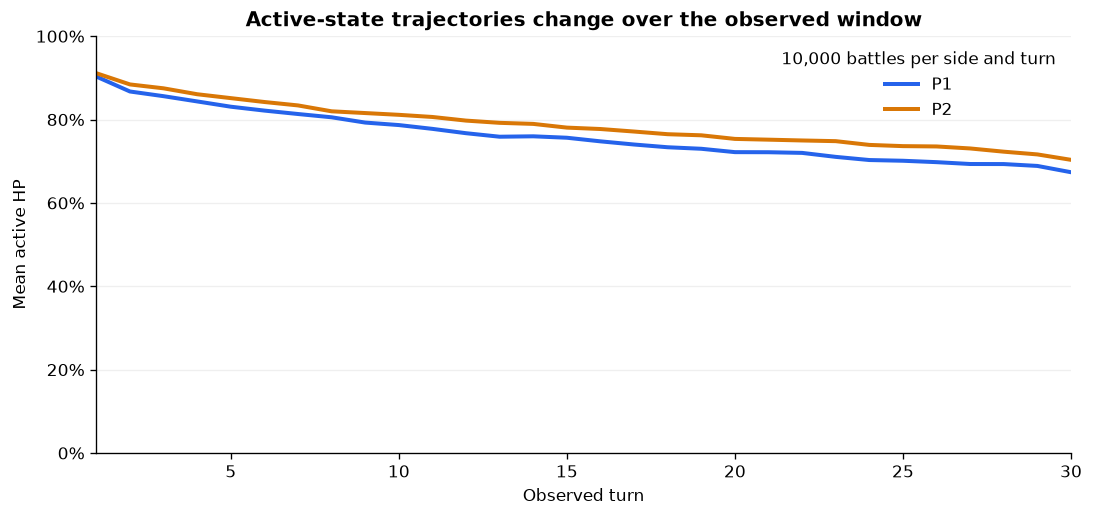

observations  mean_active_hp
side block                              
p1   1–10         100000        0.832069
     11–20        100000        0.749301
     21–30        100000        0.700285
p2   1–10         100000        0.850536
     11–20        100000        0.779523
     21–30        100000        0.733397

In [4]:
COLORS = {"p1": "#2563EB", "p2": "#D97706"}
plt.rcParams.update({"figure.dpi": 120, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold"})
hp_by_turn = snapshots.groupby(["side", "turn"], observed=True)["hp"].mean().unstack(0)
fig, ax = plt.subplots(figsize=(9, 4.2), layout="constrained")
for side in ("p1", "p2"):
    ax.plot(hp_by_turn.index, hp_by_turn[side], color=COLORS[side], linewidth=2.4, label=side.upper())
ax.set(title="Active-state trajectories change over the observed window",
       xlabel="Observed turn", ylabel="Mean active HP", xlim=(1, 30), ylim=(0, 1))
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.grid(axis="y", alpha=0.2)
ax.legend(title="10,000 battles per side and turn", frameon=False)
fig.savefig(FIGURE_DIR / "01_active_hp_by_turn.png", dpi=160)
plt.show()
window_hp = snapshots.groupby(["side", "block"], observed=True).agg(
    observations=("hp", "size"), mean_active_hp=("hp", "mean"))
display(window_hp)

Historical block means were approximately **83.21% â†’ 74.93% â†’ 70.03% P1** and **85.05% â†’ 77.95% â†’ 73.34% P2**. This motivates recent-state candidates, without establishing predictive value.

Two quantities must remain distinct: an **active-state slope** may span several Pokémon; an **adjacent same-name delta** restricts consecutive observations to the same active name. Even the latter is not damage from a specific move or proof of individual identity. The original EDA found better pair coverage in recent ten-turn than five-turn windows, motivating explicit coverage counts. Last-observed HP of a benched Pokémon is stale information, not certified current HP.

## 4. Moves, status history and first terminal observations

### 4.1 Null move cards and active-name changes

We use turns **2–30**; turn 1 has no previous active name. The denominator is the number of snapshots in each context. We estimate `P(null move | name changed)` and `P(null move | name unchanged)`, not the reverse conditional.

observations  null_cards  null_rate
side name_changed                                     
p1   False               187237        3310   0.017678
     True                102763       52738   0.513200
p2   False               188706        3695   0.019581
     True                101294       52507   0.518362

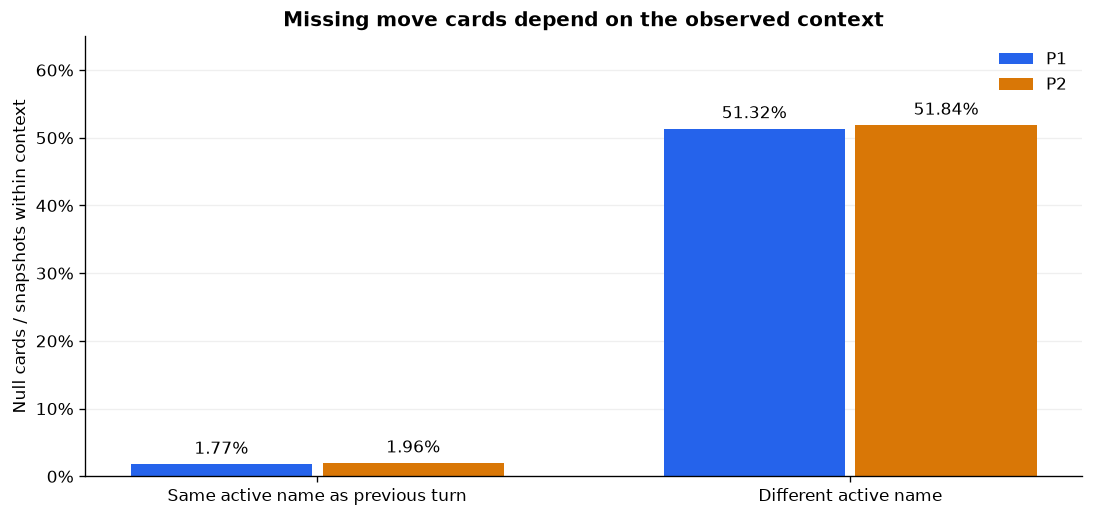

In [5]:
adjacent = snapshots.loc[snapshots["turn"].gt(1)].copy()
move_context = adjacent.groupby(["side", "name_changed"], observed=True).agg(
    observations=("move_null", "size"), null_cards=("move_null", "sum"))
move_context["null_rate"] = move_context["null_cards"] / move_context["observations"]
for key, expected in {("p1", True): (102763, 52738), ("p1", False): (187237, 3310),
                      ("p2", True): (101294, 52507), ("p2", False): (188706, 3695)}.items():
    assert tuple(move_context.loc[key, ["observations", "null_cards"]].astype(int)) == expected
display(move_context)
fig, ax = plt.subplots(figsize=(9, 4.2), layout="constrained")
x = np.arange(2)
for offset, side in zip((-0.18, 0.18), ("p1", "p2")):
    rates = [float(move_context.loc[(side, changed), "null_rate"]) for changed in (False, True)]
    bars = ax.bar(x + offset, rates, width=0.34, label=side.upper(), color=COLORS[side])
    ax.bar_label(bars, labels=[f"{100*v:.2f}%" for v in rates], padding=4)
ax.set_xticks(x, ["Same active name as previous turn", "Different active name"])
ax.set(title="Missing move cards depend on the observed context",
       ylabel="Null cards / snapshots within context", ylim=(0, 0.65))
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
ax.legend(frameon=False)
fig.savefig(FIGURE_DIR / "02_missing_moves_by_name_change.png", dpi=160)
plt.show()

About half the changed-name snapshots have a null card; nulls also occur with the same name. Neither direction defines a deterministic rule. We retain observed activity and null-card runs instead of converting every null into a synthetic switch.

A final `nostatus` also cannot reveal earlier sleep duration. Move category `status` describes the move, not a Pokémon's status code.

### 4.2 First terminal observations versus repeated snapshots

For each battle and side, scan turns 1–30 and record the **first** terminal snapshot per normalized active name: `status == 'fnt'` or finite `hp_pct <= 0`. Count those names within each block. All 10,000 battles per side enter each distribution, including zero counts.

This is the F06 observation rule in the final block. A name terminal at turns 15 and 25 is not a new late KO. No hidden losses are inferred; names do not guarantee individual identity.

battles  mean_new_terminal_names  share_with_any
side window                                                  
p1   1–10      10000                   0.3421          0.2971
     11–20     10000                   0.5826          0.4521
     21–30     10000                   0.7635          0.5269
p2   1–10      10000                   0.1093          0.1025
     11–20     10000                   0.1728          0.1578
     21–30     10000                   0.2219          0.1911

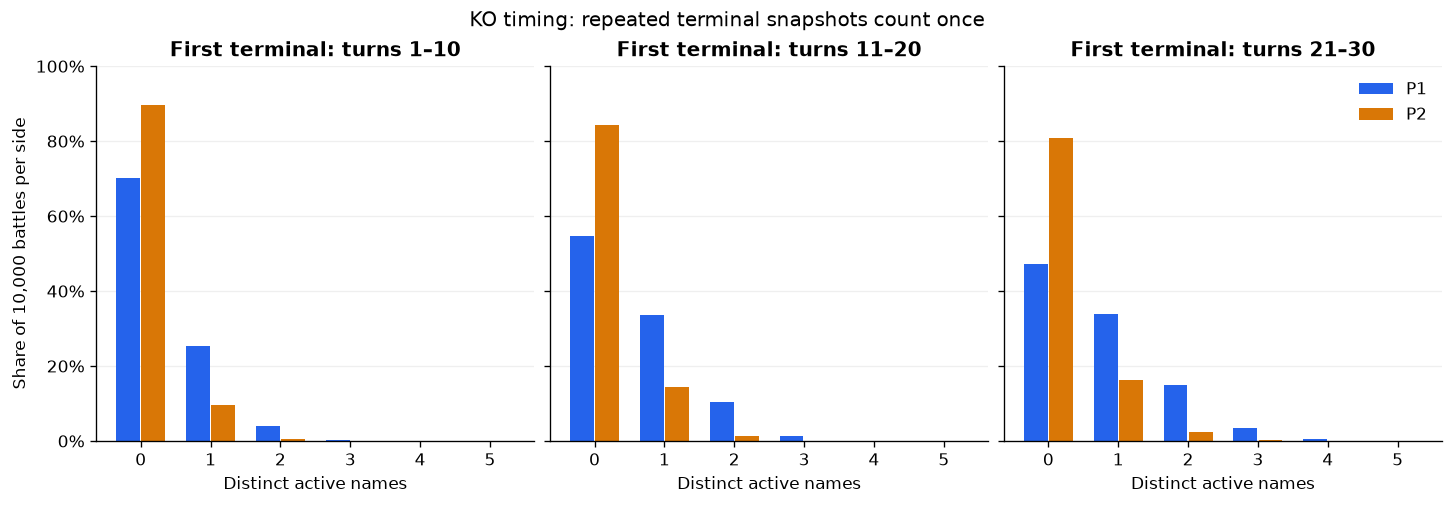

,p1_new_faint_names_t21_30,p2_new_faint_names_t21_30
count,10000.0000,10000.0000
mean,0.7635,0.2219
std,0.8744,0.4916
min,0.0000,0.0000
25%,0.0000,0.0000
50%,1.0000,0.0000
75%,1.0000,0.0000
max,5.0000,4.0000


In [6]:
windows = ["1–10", "11–20", "21–30"]
ko_summary = ko_counts.groupby(["side", "window"], sort=False).agg(
    battles=("battle_id", "size"), mean_new_terminal_names=("new_terminal_names", "mean"),
    share_with_any=("new_terminal_names", lambda x: float(x.gt(0).mean())))
display(ko_summary)
values = np.arange(int(ko_counts["new_terminal_names"].max()) + 1)
fig, axes = plt.subplots(1, 3, figsize=(12, 4.1), sharey=True, layout="constrained")
for ax, window in zip(axes, windows):
    for offset, side in zip((-0.18, 0.18), ("p1", "p2")):
        group = ko_counts.loc[ko_counts["side"].eq(side) & ko_counts["window"].eq(window), "new_terminal_names"]
        assert len(group) == 10000
        shares = group.value_counts().reindex(values, fill_value=0) / len(group)
        ax.bar(values + offset, shares, width=0.34, color=COLORS[side], label=side.upper())
    ax.set(title=f"First terminal: turns {window}", xlabel="Distinct active names", ylim=(0, 1))
    ax.set_xticks(values)
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)
axes[0].set_ylabel("Share of 10,000 battles per side")
axes[0].yaxis.set_major_formatter(PercentFormatter(1))
axes[-1].legend(frameon=False)
fig.suptitle("KO timing: repeated terminal snapshots count once", fontsize=12)
fig.savefig(FIGURE_DIR / "03_first_terminal_names_by_window.png", dpi=160)
plt.show()
f06_training = ko_counts.loc[ko_counts["window"].eq("21–30")].pivot(
    index="battle_id", columns="side", values="new_terminal_names")
f06_training.columns = [f"{side}_new_faint_names_t21_30" for side in f06_training.columns]
display(f06_training.describe().round(4))

**Interpretation.** P1 and P2 differ in exposed terminal states. That is not a direct measurement of their true loss difference. V337 counts observations and does not repair hidden P2 KOs. The final panel motivates a timing distinction; it does not measure F06's marginal contribution to Accuracy.

## 5. From EDA to the features actually used

Each battle becomes one tabular row: these are **temporal descriptors for classical ML**, not neural sequence models. The earlier 163-column F3 V1 matrix is not the feature matrix of these submissions.

| Question | Implemented examples | Meaning and limitation |
|---|---|---|
| What is visible now? | `p1_hp_turn30`, `hp_diff_turn30`, `boosts_diff_turn30` | Final active states; positive/negative boost stages can cancel in the sum. |
| What resources have appeared? | `p2_n_observed`, `p2_hp_sum_observed`, `p1_n_fainted_observed` | Latest observation per name; not simultaneous full-team telemetry. |
| Does the path matter? | `p1_hp_delta_same_name_mean`, `p2_hp_mean_t21_30`, `hp_trend_acceleration_diff` | Same-name changes, recent levels and slope changes; membership varies by component. |
| How variable are active appearances? | `active_entropy_diff` | Entropy of active-name frequencies, not roster diversity alone. |
| How do moves/statuses persist? | `attacks_rate_diff`, `sleep_streak_max_diff`, `p2_trailing_status_move_turns` | Card availability, sleep runs and status-move tails: distinct concepts. |
| What initial attributes are supplied? | Team stats, P1 slot-item one-hot, `p2_lookup_hp_weighted_fraction` | Supplied cards and a training-derived base-HP lookup, not external data. |
| When are new KOs observed? | `p1_new_faint_names_t21_30`, `p2_new_faint_names_t21_30` | F06 pair added only to V337 CatBoost. |

The manifest provides the exact ordered column lists and serialized pipeline settings. The following tables are read from it, avoiding a second manually maintained parameter dictionary.

In [7]:
recipe_rows, parameter_rows = [], []
for recipe_id in RECIPE_IDS:
    recipe = MANIFEST["recipes"][recipe_id]
    recipe_rows.append({"recipe": recipe_id, **recipe["model_feature_counts"]})
    for component, spec in recipe["model_specifications"].items():
        last = spec["pipeline_steps"][-1]
        params = last["parameters"]
        keys = ["iterations", "n_estimators", "depth", "max_depth", "learning_rate",
                "min_child_weight", "subsample", "colsample_bytree", "reg_alpha",
                "reg_lambda", "C", "solver", "max_iter", "random_seed", "random_state"]
        parameter_rows.append({"recipe": recipe_id, "component": component,
                               "estimator": last["class"].split(".")[-1],
                               "parameters": {k: params[k] for k in keys if k in params}})
display(pd.DataFrame(recipe_rows).set_index("recipe"))
# Show each component once; per-recipe complete settings remain in the manifest.
with pd.option_context("display.max_colwidth", 220):
    display(pd.DataFrame(parameter_rows).query("recipe == 'v337_cat_f06_pair'"))

,CatBoost,XGBoost,LogisticRegression_C10,LR_C10
recipe,,,,
c09,80,142,143.0,NaN
v334_highest_mean,86,142,NaN,145.0
v337_cat_f06_pair,82,142,NaN,143.0


,recipe,component,estimator,parameters
6,v337_cat_f06_pair,CatBoost,CatBoostClassifier,"{'iterations': 350, 'depth': 6, 'learning_rate': 0.05, 'random_seed': 42}"
7,v337_cat_f06_pair,LR_C10,LogisticRegression,"{'C': 10.0, 'solver': 'lbfgs', 'max_iter': 2000, 'random_state': 44}"
8,v337_cat_f06_pair,XGBoost,XGBClassifier,"{'n_estimators': 350, 'max_depth': 3, 'learning_rate': 0.05, 'min_child_weight': 5, 'subsample': 0.8, 'colsample_bytree': 0.8, 'reg_alpha': 0.1, 'reg_lambda': 5, 'random_state': 42}"


### 5.1 C09: component-specific bases plus 13 temporal descriptors

C09 uses **80 CatBoost / 142 XGBoost / 143 LR columns**. Its six PM2 and seven Submission2 additions are shared; other base columns differ. Item one-hot columns enter XGBoost and LR. The final CatBoost matrix is numerical; it does not use native categorical encoding.

**Six PM2 columns:**

- `p2_worst_hp_turn`: first turn attaining the minimum active HP for P2 (`argmin`, turns 1–30).
- `hp_trend_acceleration_diff`: slope on turns 16–30 minus slope on 1–15 for each side, then P1 minus P2. This is an active-state trend change, not physical acceleration of one Pokémon's HP.
- `p1_status_immediately_after_switch`, `p2_status_immediately_after_switch`: historical names for counts after active-name changes, where the following status differs from the current one and is not `nostatus`. **Legacy naming: `p1_` uses P2 snapshots and `p2_` uses P1 snapshots.**
- `p1_status_duration_total`, `p2_status_duration_total`: counts of turns 2–30 with a status other than `nostatus`, including `fnt`. These are not single-episode durations. **These names are also side-swapped.**

We retain the historical names/formulas to reproduce the submissions; redefining them would require retraining and a new experiment.

**Seven Submission2 columns:**

- `active_entropy_diff`: `H(P1 active-name frequencies) âˆ’ H(P2)`, with natural logarithms.
- `status_turns_advantage`: summed severity P1 minus P2; `par/brn/psn=1`, `tox/frz=2`, `slp=3`, `nostatus/fnt=0`. These are chosen weights. Despite the name, a positive value means greater recorded burden on P1.
- `hp_gap_peak_turn_share`: first turn maximizing **P2 HP minus P1 HP**, divided by 30.
- `hp_gap_sign_flips`: adjacent sign changes with both gaps nonzero; zeros interrupt the counted transition.
- `attacks_rate_diff`: difference in nonempty recorded move-name counts divided by 30, including status moves. It does not count successful damaging attacks.
- `substitute_late_share_diff`: difference in fractions of turns 21–30 with `substitute` in observed effects.
- `sleep_streak_max_diff`: difference in longest `slp` runs in the active-state timelines; no same-name continuity restriction.

**Preprocessing and lookup:** pipelines use median imputation; LR adds StandardScaler and L2 regularization (`C=10`). P1 slot-item OneHotEncoder uses `min_frequency=5`, `handle_unknown=ignore`. P2 base HP is looked up from supplied training cards: conflicting species are excluded, and the record's local lead takes precedence. The weighted fraction covers observed names with known base HP; it is not true total team health.

### 5.2 Highest mean: model-specific additions

CatBoost adds F02/F04/N02/N03/N04; XGBoost stays C09; LR adds F02/N03. Counts: **86 / 142 / 145**.

| Token | Exact observation summarized |
|---|---|
| F02 | `p2_trailing_status_move_turns`: consecutive status-category cards backwards from turn 30; a null or non-status card stops the run. |
| F04 | `move_made_diff_mean_recent10_context`: P1 minus P2 fraction of non-null move cards in turns 21–30. |
| N02 | `encounter_hp_delta_p2_mean`: segments with a constant **pair of P1/P2 active names**; mean of P2 last-minus-first HP per segment, including singleton zero deltas. |
| N03 | `p2_lead_type_fighting`: supplied initial P2 lead has Fighting among its types. |
| N04 | `p1_no_move_record_run_max_t21_30`, `p2_no_move_record_run_max_t21_30`: longest consecutive null-card run within turns 21–30. |

These are recorded contexts, not move success or causal damage. Pokémon types and **move-type effectiveness multipliers are distinct**: this payload does not load `type_chart_gen2.csv` or apply its multipliers. A Fighting lead indicator is not a damage multiplier.

### 5.3 V337: F06 only for CatBoost

V337 adds the two late first-terminal-name counts only to CatBoost: **82 / 142 / 143 columns**. XGBoost and LR retain C09. Both F06 columns require the entire 1–30 prefix to exclude earlier first terminal observations.

On two selection splits the blend gained **25 and 23 correct predictions out of 8,000** against C09 (+0.3125 and +0.2875 percentage points). Historical split checks subsequently lost **24 and 12** correct predictions. Thus F06 was promising on some splits, not stably positive everywhere. Its 69.8% public score does not isolate a causal gain from those two features.

## 6. Validation and results: different scores answer different questions

**Accuracy = correctly classified battles / evaluated battles.** The three final models average component probabilities equally:

`p_blend = (p_CatBoost + p_XGBoost + p_LR) / 3`; predict P1 victory if `p_blend >= 0.5`.

Historical selection used grouped five-fold OOF on **8,000 development rows**, keeping duplicates according to the experiment's equivalence rule in one fold. Highest mean documents 7,874 groups. Grouping definitions evolved; same team composition alone need not mean an identical battle. Grouping reduces leakage for its chosen equivalence relation, not all possible dependencies.

Learned preprocessing, item vocabularies and lookups must be fitted on training folds for historical validation. The final runner uses all 10,000 training rows to rebuild lookups/encoding and optionally retrain estimators. This is intentional full-data inference/refit, **not CV evaluation**.

Development labels were reused across many experiments: the OOF scores below are exploratory. Seeds reuse the same battles and are not independent test sets. This notebook does not rerun feature search or OOF. An earlier 2,000-row holdout score for XGBoost F3 does not evaluate these later blends; those rows are included in final full-data refits.

In [8]:
oof_rows = []
for recipe_id in RECIPE_IDS:
    evidence = MANIFEST["recipes"][recipe_id]["source_oof"]
    if recipe_id == "c09":
        entries = evidence["blend_accuracy"]
    elif recipe_id == "v334_highest_mean":
        entries = [{"seed": int(seed), "accuracy": accuracy,
                    "correct": evidence["correct_by_seed"][f"seed{seed}_correct"]}
                   for seed, accuracy in evidence["accuracy_by_seed"].items()]
    else:
        entries = evidence
    for entry in entries:
        oof_rows.append({"recipe": recipe_id, "split_seed": entry["seed"],
                         "correct": entry["correct"], "development_rows": 8000,
                         "historical_OOF_accuracy": entry["accuracy"]})
print("Historical evidence from the manifest; no OOF experiment rerun here.")
display(pd.DataFrame(oof_rows))
scores = pd.DataFrame([
    {"recipe": rid, "public_accuracy": float(MANIFEST["recipes"][rid]["reported_leaderboard_score"]),
     "private_accuracy": float(MANIFEST["recipes"][rid]["reported_private_score"])}
    for rid in RECIPE_IDS])
scores["public_minus_private_pp"] = 100 * (scores["public_accuracy"] - scores["private_accuracy"])
print("Kaggle scores reported by the team; not queried or independently verified here.")
display(scores)

,recipe,split_seed,correct,development_rows,historical_OOF_accuracy
0,c09,43,5477,8000,0.684625
1,c09,2027,5468,8000,0.683500
2,v334_highest_mean,43,5475,8000,0.684375
3,v334_highest_mean,2027,5499,8000,0.687375
4,v337_cat_f06_pair,31415,5500,8000,0.687500
5,v337_cat_f06_pair,8675309,5457,8000,0.682125


,recipe,public_accuracy,private_accuracy,public_minus_private_pp
0,c09,0.69333,0.65914,3.419
1,v334_highest_mean,0.69266,0.66457,2.809
2,v337_cat_f06_pair,0.69800,0.66285,3.515


Historical evidence from the manifest; no OOF experiment rerun here.
Kaggle scores reported by the team; not queried or independently verified here.


**Outcome:** V337 is best public (69.800%), while **highest mean is best private among these three (66.457%)**. Final ranking uses the private leaderboard. Its private advantage over V337 is just 0.172 percentage points; without test labels and paired errors, we do not claim statistical significance.

Public-to-private drops are 3.419 points for C09, 2.809 for highest mean and 3.515 for V337. They reveal a generalization limitation without identifying its cause: sampling variation, distribution differences and selection effects cannot be separated with these scores. OOF, public and private are distinct evaluations, not quantities to pool. None of these submissions reaches 70% private Accuracy.

## 7. Reproduce the selected submissions

The next cell runs the existing, verified pipeline for all three recipes:

1. **C09:** component-specific bases and the 13 temporal additions; `c09/submission.csv`.
2. **Highest mean:** the model-specific token expansion in section 5.2; `v334_highest_mean/submission.csv`.
3. **V337 F06 pair:** F06 added only to CatBoost; `v337_cat_f06_pair/submission.csv`.

The runner verifies source/model integrity, rebuilds training-derived lookups and encoding, checks test/sample IDs and order, and validates the exact CSV hashes. `REFIT_MODELS=False` loads estimators already fitted on all 10,000 rows; `True` clones their configurations and performs a new full-data fit. Both modes stop if CSV bytes differ from their recorded originals. Refit numerical behaviour may depend on the environment.

No test label is read; an unexpected `player_won` in test is rejected. EDA uses training records only and does not alter the chosen features or thresholds.

In [9]:
# Release large descriptive tables before the runner loads train/test in a subprocess.
del train_records, snapshots, adjacent
import gc
gc.collect()
command = [sys.executable, str(PACKAGE_DIR / "run_submissions.py"),
           "--data-dir", str(DATA_DIR), "--output-dir", str(OUTPUT_DIR / "submissions")]
if REFIT_MODELS:
    command.append("--refit-models")
result = subprocess.run(command, cwd=PACKAGE_DIR, capture_output=True, text=True)
if result.returncode:
    print(result.stdout)
    print(result.stderr)
result.check_returncode()
print("Runner completed: all three CSV hashes match the selected originals.")

Runner completed: all three CSV hashes match the selected originals.


In [10]:
verification = []
for recipe_id in RECIPE_IDS:
    csv_path = OUTPUT_DIR / "submissions" / recipe_id / "submission.csv"
    frame = pd.read_csv(csv_path)
    actual_hash = hashlib.sha256(csv_path.read_bytes()).hexdigest()
    expected_hash = MANIFEST["recipes"][recipe_id]["submission_sha256"]
    assert list(frame.columns) == ["battle_id", "player_won"]
    assert len(frame) == 5000 and frame["battle_id"].is_unique
    assert frame["player_won"].isin([0, 1]).all() and actual_hash == expected_hash
    verification.append({"recipe": recipe_id, "rows": len(frame),
                         "exact_hash_match": actual_hash == expected_hash,
                         "output_relative_path": str(csv_path.relative_to(OUTPUT_DIR))})
display(pd.DataFrame(verification))
print("Download only the three submission.csv files; component_predictions.csv is diagnostic.")

,recipe,rows,exact_hash_match,output_relative_path
0,c09,5000,True,submissions\c09\submission.csv
1,v334_highest_mean,5000,True,submissions\v334_highest_mean\submission.csv
2,v337_cat_f06_pair,5000,True,submissions\v337_cat_f06_pair\submission.csv


Download only the three submission.csv files; component_predictions.csv is diagnostic.


## 8. Conclusions, provenance and limitations

Asymmetric visibility, observation patterns and temporal history motivate richer representations than the final active snapshot alone. **Ablation and validation measure predictive usefulness; descriptive plots do not.** The strongest private score among the selected submissions is 66.457%; split sensitivity, incomplete KO visibility and stale/name-based resource estimates remain limitations.

The exact columns, parameters and hashes are in [manifest.json](manifest.json); the shared pipeline is [run_submissions.py](run_submissions.py). See [README.md](README.md), [requirements-notebook.txt](requirements-notebook.txt). This notebook uses the current Git checkout; record an immutable Git revision when publishing the final version.

The historical EDA was developed in the original project's `src/eda/` and `experiment/eda/` HP/moves/interactions reports. Its main observations are recomputed here: the public payload does not need those local files or the wiki. Training-only descriptive exploration includes all 10,000 rows; this does not mean a later holdout was unseen in every sense. Old duplicate counts are intentionally omitted without their exact identity definition.

No new model search, OOF evaluation, importance attribution, causal inference, hidden-KO repair, external chart enrichment or Kaggle upload is performed here. Another team's post-competition code was not incorporated into the submitted models. Further observation reconstruction and nested selection are possible future experiments, not results of this walkthrough.